# Week 3 – Supervised Models on an Urdu News Dataset (FAKE vs TRUE)

**Problem:** Given one Urdu news headline/item, predict whether it is **FAKE** or **TRUE**.

**Models:** KNN, Decision Tree, Logistic Regression (plus Linear Regression as an extra, used as a classifier with a 0.5 cut-off).

**Metrics:** Accuracy, confusion matrix, precision, recall, F1-score.

> Note on the dataset: the assignment asks for mostly numeric columns. This dataset is *text* (Urdu sentences), so in Step 1 I turn the text into numbers (TF-IDF scores + word/character counts) before any model sees it.

## Step 1 – Prepare the data
Plan for this step: load the file → check missing values and duplicates → fix them → encode the text label → look at class balance → 80/20 stratified split → turn text into numbers → scale (fit on train only).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

### 1.1 Load the data and look at it

In [2]:
df = pd.read_csv("urdu_news.csv")
print("Shape:", df.shape)
print(df.dtypes)
df.head()

Shape: (10106, 3)
Sr. No.       str
News Items    str
Label         str
dtype: object


,Sr. No.,News Items,Label
0,1,ٹی ٹی پی نے پنجاب حکومت کے ہیلی کاپٹر کے عملے ...,FAKE
1,2,مارک زکربرگ سیاست میں آنے کا سوچ رہے ہیں۔,FAKE
2,3,فریدہ جلال نے اپنی موت کی افواہوں پر تنقید کی۔,FAKE
3,4,جعلی خبریں: پاپ اسٹار حدیقہ کیانی نے جعلی منشی...,FAKE
4,5,صنم ماروی نے میڈیا پر گردش کرنے والی زیادتی او...,FAKE


### 1.2 Check missing values, duplicates and odd labels
Before fixing anything I want to see what is wrong. I check (a) empty cells, (b) fully duplicated rows, (c) repeated news text, and (d) what values the `Label` column really contains.

In [3]:
print("Missing values per column:")
print(df.isna().sum())
print()
print("Fully duplicated rows:", df.duplicated().sum())
print("Repeated news text   :", df["News Items"].duplicated().sum())
print()
print("Label values exactly as stored:")
print(df["Label"].map(repr).value_counts())

Missing values per column:
Sr. No.       22
News Items    22
Label         22
dtype: int64

Fully duplicated rows: 21
Repeated news text   : 869

Label values exactly as stored:
Label
'FAKE'     5039
'TRUE'     4997
'TRUE '      33
nan          22
'FAKE '      14
'Label'       1
Name: count, dtype: int64


What I found: some rows have empty cells, there is a stray row where the label is literally the word `Label` (a second header line from joining two files – the `Sr. No.` numbering also restarts at 1 half-way), a few labels have a trailing space (`'TRUE '`, `'FAKE '`), and many news texts appear more than once. I fix all of this below. I also drop `Sr. No.` because it is only a row number and has nothing to do with the news content.

In [4]:
clean = df.copy()

# 1) remove rows with no text or no label
clean = clean.dropna(subset=["News Items", "Label"])

# 2) tidy label text (remove spaces) and drop the stray 'Label' header row
clean["Label"] = clean["Label"].str.strip().str.upper()
clean = clean[clean["Label"].isin(["FAKE", "TRUE"])]

# 3) check: does any text appear with BOTH labels? (that would be contradictory)
conflict = (clean.groupby("News Items")["Label"].nunique() > 1).sum()
print("Texts with conflicting labels:", conflict)

# 4) drop repeated texts so the same sentence cannot be in both train and test
clean = clean.drop_duplicates(subset=["News Items"]).reset_index(drop=True)

# 5) drop the useless row-number column and rename for convenience
clean = clean.drop(columns=["Sr. No."]).rename(columns={"News Items": "text", "Label": "label"})

print(f"Rows before: {len(df)}  ->  rows after cleaning: {len(clean)}")
print("Missing values now:", clean.isna().sum().sum(), "| duplicates now:", clean.duplicated().sum())

Texts with conflicting labels: 0
Rows before: 10106  ->  rows after cleaning: 9235
Missing values now: 0 | duplicates now: 0


### 1.3 Encode the text label
Models need numbers, so I encode **FAKE = 1** and **TRUE = 0**. I made FAKE the "positive" class on purpose: the job of this system is to *catch fake news*, so precision/recall in the report will be about the FAKE class.

In [5]:
clean["target"] = (clean["label"] == "FAKE").astype(int)

# Two simple numeric columns that describe the text itself
clean["word_count"] = clean["text"].str.split().str.len()
clean["char_count"] = clean["text"].str.len()

clean[["label", "target", "word_count", "char_count"]].head()

,label,target,word_count,char_count
0,FAKE,1,18,77
1,FAKE,1,9,41
2,FAKE,1,10,46
3,FAKE,1,18,90
4,FAKE,1,18,85


### 1.4 How many rows belong to each class? (balanced or not?)

label
FAKE    4637
TRUE    4598
Name: count, dtype: int64

label
FAKE    50.21 %
TRUE    49.79 %
Name: proportion, dtype: str


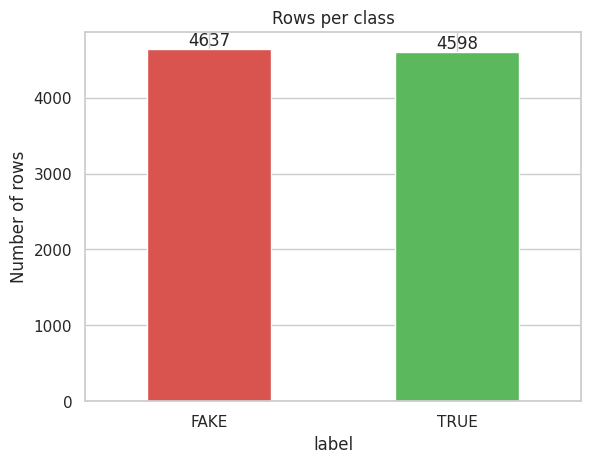

In [6]:
counts = clean["label"].value_counts()
print(counts)
print()
print((clean["label"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

ax = counts.plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0)
ax.set_title("Rows per class")
ax.set_ylabel("Number of rows")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()

**Balanced or not?** The data is almost perfectly balanced: 4,637 FAKE (50.2 %) and 4,598 TRUE (49.8 %). So a model that guesses at random would score about 50 %, and that is the number every model has to beat. Because of this balance, accuracy is a fair first metric here (I test this properly in the BONUS section).

### 1.5 Train/test split (80/20, `stratify=y`, `random_state=42`)
I split the **raw text first**. The reason: the TF-IDF vocabulary must be learned from the training text only. If I built the vocabulary on all rows, information from the test set would leak into training.

In [7]:
X_text = clean[["text", "word_count", "char_count"]]
y = clean["target"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train rows:", len(X_train_raw), "| Test rows:", len(X_test_raw))
print("FAKE share  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Train rows: 7388 | Test rows: 1847
FAKE share  train: 0.502  test: 0.502


### 1.6 Turn text into numbers (TF-IDF) and scale
* `TfidfVectorizer(max_features=500)` keeps the 500 most useful words. It is **fit on the training text only**; the test text is only transformed.
* I add `word_count` and `char_count` as two extra numeric columns.
* `StandardScaler`: `fit_transform` on train, only `transform` on test (no data leakage).

In [8]:
tfidf = TfidfVectorizer(max_features=500)

train_tfidf = tfidf.fit_transform(X_train_raw["text"]).toarray()   # fit on TRAIN only
test_tfidf  = tfidf.transform(X_test_raw["text"]).toarray()        # only transform TEST

X_train_num = np.hstack([train_tfidf, X_train_raw[["word_count", "char_count"]].values])
X_test_num  = np.hstack([test_tfidf,  X_test_raw[["word_count", "char_count"]].values])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_num)   # fit on TRAIN only
X_test  = scaler.transform(X_test_num)        # transform TEST with train's mean/std

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (7388, 502) | X_test: (1847, 502)


## Step 2 – K-Nearest Neighbours
First the required model with `n_neighbors=5`, then every odd K from 1 to 15. For each K I record the accuracy on the training set and the test set, then plot K against accuracy.

In [9]:
knn5 = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("KNN (K=5) test accuracy:", round(accuracy_score(y_test, knn5.predict(X_test)), 4))

KNN (K=5) test accuracy: 0.6562


 K  train_acc  test_acc
 1     1.0000    0.6524
 3     0.8115    0.6530
 5     0.7618    0.6562
 7     0.7396    0.6535
 9     0.7210    0.6454
11     0.7143    0.6530
13     0.7003    0.6459
15     0.6864    0.6416

Best K (highest test accuracy): 5


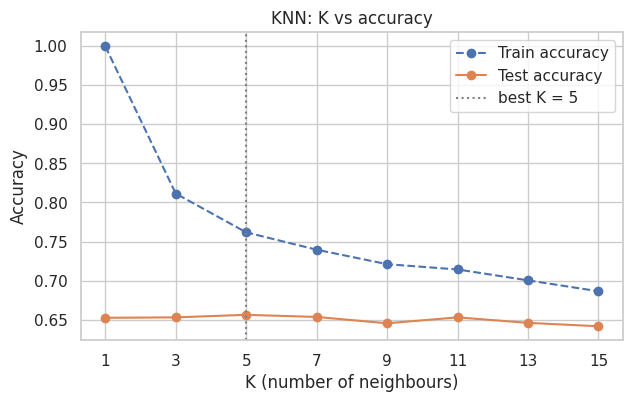

In [10]:
k_values = list(range(1, 16, 2))          # 1, 3, 5, ..., 15
knn_train_acc, knn_test_acc = [], []

for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    knn_train_acc.append(accuracy_score(y_train, m.predict(X_train)))
    knn_test_acc.append(accuracy_score(y_test, m.predict(X_test)))

knn_results = pd.DataFrame({"K": k_values, "train_acc": knn_train_acc, "test_acc": knn_test_acc})
print(knn_results.round(4).to_string(index=False))

best_k = k_values[int(np.argmax(knn_test_acc))]
print("\nBest K (highest test accuracy):", best_k)

plt.figure(figsize=(7, 4))
plt.plot(k_values, knn_train_acc, "o--", label="Train accuracy")
plt.plot(k_values, knn_test_acc, "o-", label="Test accuracy")
plt.axvline(best_k, color="grey", linestyle=":", label=f"best K = {best_k}")
plt.xticks(k_values); plt.xlabel("K (number of neighbours)"); plt.ylabel("Accuracy")
plt.title("KNN: K vs accuracy"); plt.legend(); plt.show()

**What I see:** KNN is weak on this data. Test accuracy stays between about 64 % and 66 % for every K, and K = 5 is the best (65.6 %). With K = 1 the training accuracy is 100 % because each point is its own nearest neighbour, but test accuracy is no better, so K = 1 only memorises. The likely reason is that the data has 502 columns, most of them zeros (a sentence only uses a few of the 500 words). In so many dimensions, "nearest" points are not really more similar, so the neighbours' votes are not very informative.

## Step 3 – Decision Tree
I train a tree with `max_depth` = 2, 3, 5, 10 and `None` (no limit) and compare train vs test accuracy. A big gap between the two is the sign of overfitting.

max_depth  train_acc  test_acc  leaves     gap
        2     0.7508    0.7477       4  0.0031
        3     0.7566    0.7574       8 -0.0008
        5     0.7884    0.7656      25  0.0229
       10     0.8277    0.7791     108  0.0486
     None     1.0000    0.7721     774  0.2279

Best max_depth by test accuracy: 10


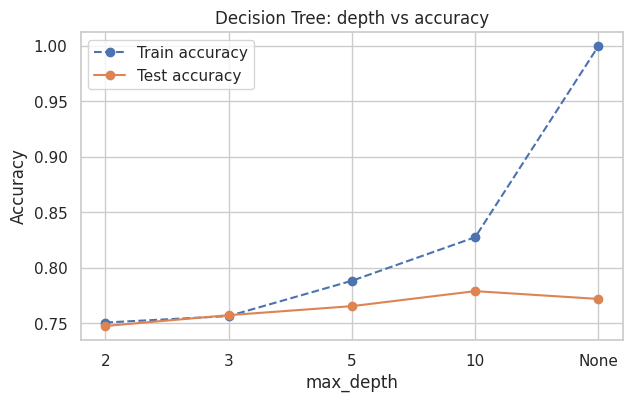

In [11]:
depths = [2, 3, 5, 10, None]
dt_rows = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    dt_rows.append({"max_depth": "None" if d is None else d,
                    "train_acc": accuracy_score(y_train, m.predict(X_train)),
                    "test_acc": accuracy_score(y_test, m.predict(X_test)),
                    "leaves": m.get_n_leaves()})
dt_results = pd.DataFrame(dt_rows)
dt_results["gap"] = dt_results["train_acc"] - dt_results["test_acc"]
print(dt_results.round(4).to_string(index=False))

best_depth_idx = int(dt_results["test_acc"].idxmax())
best_depth = depths[best_depth_idx]
print("\nBest max_depth by test accuracy:", best_depth)

x = range(len(depths))
plt.figure(figsize=(7, 4))
plt.plot(x, dt_results["train_acc"], "o--", label="Train accuracy")
plt.plot(x, dt_results["test_acc"], "o-", label="Test accuracy")
plt.xticks(x, dt_results["max_depth"].astype(str)); plt.xlabel("max_depth")
plt.ylabel("Accuracy"); plt.title("Decision Tree: depth vs accuracy"); plt.legend(); plt.show()

**What happens when the tree is very deep:** with `max_depth=None` the tree grows 774 leaves and gets **100 % training accuracy but only 77.2 % test accuracy**, a gap of about 23 points. It has memorised the training sentences, including their noise, instead of learning a general rule (overfitting). A very shallow tree (depth 2 or 3) has the opposite problem: train and test are both about 75 %, so it is too simple (underfitting). Depth 10 gave the best test accuracy (77.9 %) with a much smaller gap (about 5 points), so it is the best balance. Depth 5 is a safer, simpler choice, but it is about 1.3 points lower.

## Step 4 – Logistic Regression
Train `LogisticRegression` and look at `predict_proba` for 5 test rows. Column 0 is P(TRUE) and column 1 is P(FAKE); the model predicts FAKE when P(FAKE) ≥ 0.5.

In [12]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train, y_train)
print("Logistic Regression test accuracy:", round(accuracy_score(y_test, log_reg.predict(X_test)), 4))

proba = log_reg.predict_proba(X_test[:5])
proba_table = pd.DataFrame({
    "P(TRUE)": proba[:, 0].round(3),
    "P(FAKE)": proba[:, 1].round(3),
    "predicted": np.where(proba[:, 1] >= 0.5, "FAKE", "TRUE"),
    "actual": np.where(y_test.iloc[:5].values == 1, "FAKE", "TRUE")})
proba_table

Logistic Regression test accuracy: 0.8316


,P(TRUE),P(FAKE),predicted,actual
0,0.534,0.466,TRUE,TRUE
1,0.100,0.900,FAKE,FAKE
2,0.486,0.514,FAKE,FAKE
3,0.082,0.918,FAKE,FAKE
4,0.460,0.540,FAKE,TRUE


**Reading the probabilities:** each row shows how sure the model is. Row 1 has P(FAKE) = 0.900, a confident and correct FAKE. Rows 0, 2 and 4 are close to 0.5, so the model is unsure there, and row 4 (P(FAKE) = 0.540) is a real mistake: a TRUE headline predicted as FAKE with only a small margin. This is a useful advantage over KNN and the tree, which only give a hard answer: the probability tells me *how much to trust* each prediction, and I could change the 0.5 cut-off if I wanted fewer missed fakes.

### Step 4b – Linear Regression (extra model from the goal line)
Linear Regression predicts a *number*, not a class. To use it as a classifier I fit it on the 0/1 target and call a row FAKE when the predicted number is ≥ 0.5. I also check how many predictions fall outside the 0–1 range, which a probability should never do.

In [13]:
lin_reg = LinearRegression().fit(X_train, y_train)
lin_scores = lin_reg.predict(X_test)
lin_pred = (lin_scores >= 0.5).astype(int)

print("Linear Regression (cut-off 0.5) test accuracy:", round(accuracy_score(y_test, lin_pred), 4))
print("Predictions below 0 or above 1: %.1f %%" % (100 * np.mean((lin_scores < 0) | (lin_scores > 1))))

Linear Regression (cut-off 0.5) test accuracy: 0.8078
Predictions below 0 or above 1: 14.7 %


**Why this is not the right tool:** Linear Regression still reaches 80.8 % accuracy, which is close to the others, but about 14.7 % of its predictions fall below 0 or above 1. A prediction of, say, 1.3 cannot be a probability, so it only works here because I cut it at 0.5. It is a regression model being forced to classify. Logistic Regression squeezes the output into 0–1 with the sigmoid function and is built for this job, and it scores higher (83.2 %).

## Step 5 – Evaluate all models
For every model: accuracy, confusion matrix (heat-map) and classification report. KNN uses the best K and the tree uses the best depth found above. The positive class is **FAKE (1)**.

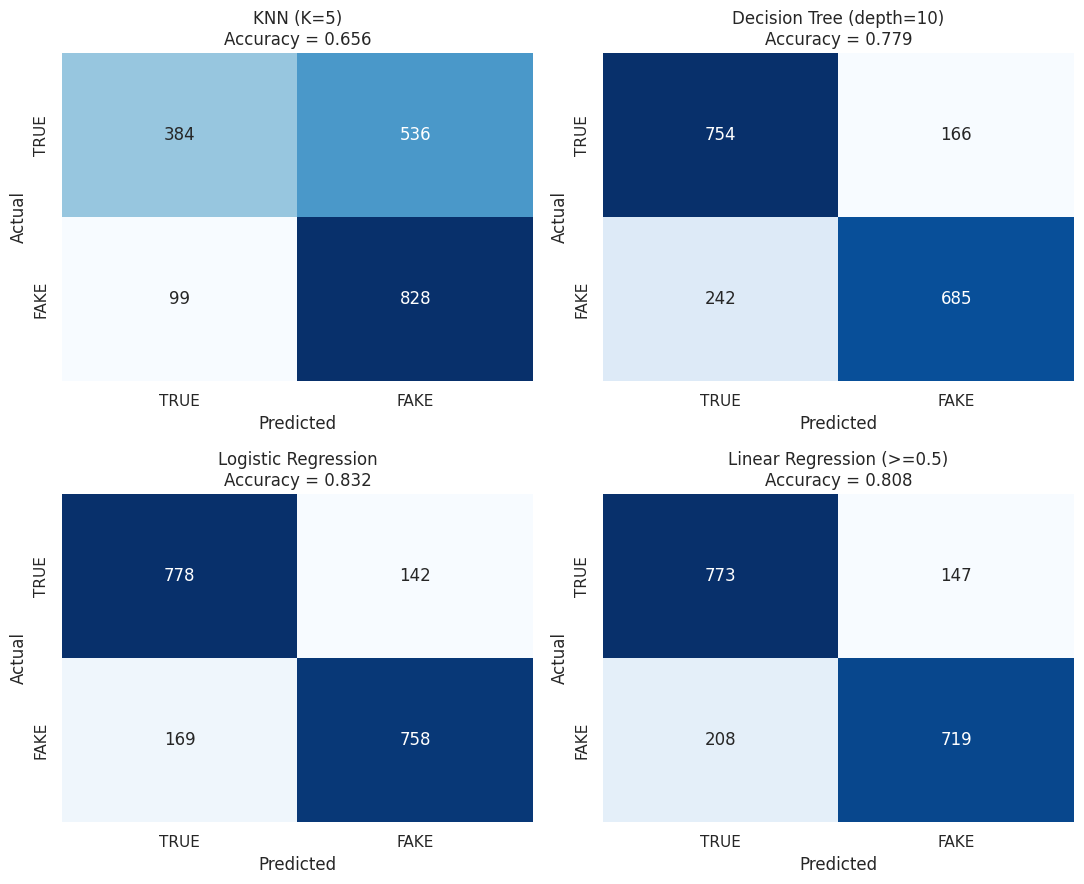

In [14]:
final_models = {
    f"KNN (K={best_k})": KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train),
    f"Decision Tree (depth={best_depth})": DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE).fit(X_train, y_train),
    "Logistic Regression": log_reg,
}
predictions = {name: m.predict(X_test) for name, m in final_models.items()}
predictions["Linear Regression (>=0.5)"] = lin_pred

class_names = ["TRUE", "FAKE"]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, pred):.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [15]:
for name, pred in predictions.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, target_names=class_names, digits=3))

KNN (K=5)
              precision    recall  f1-score   support

        TRUE      0.795     0.417     0.547       920
        FAKE      0.607     0.893     0.723       927

    accuracy                          0.656      1847
   macro avg      0.701     0.655     0.635      1847
weighted avg      0.701     0.656     0.635      1847

Decision Tree (depth=10)
              precision    recall  f1-score   support

        TRUE      0.757     0.820     0.787       920
        FAKE      0.805     0.739     0.771       927

    accuracy                          0.779      1847
   macro avg      0.781     0.779     0.779      1847
weighted avg      0.781     0.779     0.779      1847

Logistic Regression
              precision    recall  f1-score   support

        TRUE      0.822     0.846     0.833       920
        FAKE      0.842     0.818     0.830       927

    accuracy                          0.832      1847
   macro avg      0.832     0.832     0.832      1847
weighted avg      0

### Comparison table (precision, recall, F1 are for the FAKE class)

In [16]:
rows = []
for name, pred in predictions.items():
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
comparison = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
comparison.round(4)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8316,0.8422,0.8177,0.8298
1,Linear Regression (>=0.5),0.8078,0.8303,0.7756,0.8020
2,Decision Tree (depth=10),0.7791,0.8049,0.7389,0.7705
3,KNN (K=5),0.6562,0.6070,0.8932,0.7228


## Step 6 – Explain the results (my own words)

### 6.1 Which model is best and why?
**Logistic Regression is the best model** on every metric: accuracy 0.832, precision 0.842, recall 0.818 and F1 0.830. The next best are Linear Regression (0.808), the Decision Tree (0.779) and KNN (0.656). I think a linear model wins because, with TF-IDF word scores, fake and real news differ by *which words appear* and a weighted sum of word scores captures that well. KNN suffers from the many sparse columns, and the tree has to split on one word at a time and overfits when deep. Logistic Regression also gives probabilities and is fast to train.

KNN's row needs a careful look: its recall for FAKE (0.893) is the highest of all models, but that is because it labels far too many items as FAKE (it only recognises 41.7 % of the TRUE items). High recall alone is not a good sign here; its precision of 0.607 shows the cost.

### 6.2 Which mistake is worse for my problem?
For a fake-news detector I think a **false negative** (a FAKE item predicted as TRUE) is the worse mistake, because then a false story is passed on as trustworthy and people may believe and share it. A **false positive** (a real item flagged FAKE) is also bad, since real news gets wrongly blocked and people lose trust in the tool, but a human reviewer can fix it afterwards, which is easier than undoing the damage of a fake story that already spread.

So **recall for the FAKE class matters more**: it measures how many of the real fakes we catch. But I should not look at recall alone, because KNN shows how a model can get high recall by calling everything FAKE. Precision keeps that in check, so the **F1-score** (which combines the two) is the metric I would use to pick the model, with recall as the tie-breaker. Logistic Regression has the best F1 (0.830) and a recall of 0.818, so it is a good choice on both counts.

### 6.3 Where does the best model make mistakes?

In [17]:
best_name = comparison.loc[0, "Model"]
best_pred = predictions[best_name]
print("Best model:", best_name)

tn, fp, fn, tp = confusion_matrix(y_test, best_pred).ravel()
print(f"True TRUE predicted TRUE (TN): {tn}")
print(f"True TRUE predicted FAKE (FP): {fp}   <- real news wrongly flagged")
print(f"True FAKE predicted TRUE (FN): {fn}   <- fake news that slipped through")
print(f"True FAKE predicted FAKE (TP): {tp}")

# Do the mistakes depend on how long the text is?
errors = X_test_raw.copy()
errors["actual"] = y_test.values
errors["pred"] = best_pred
errors["correct"] = errors["actual"] == errors["pred"]
errors["length_group"] = pd.qcut(errors["word_count"], 4,
                                 labels=["shortest 25%", "short-mid", "long-mid", "longest 25%"])
print()
print("Accuracy by text length (word_count quartiles):")
print(errors.groupby("length_group", observed=True)["correct"].mean().round(3))
print()
print("Median word count -> correct:", errors.loc[errors.correct, "word_count"].median(),
      "| wrong:", errors.loc[~errors.correct, "word_count"].median())

Best model: Logistic Regression
True TRUE predicted TRUE (TN): 778
True TRUE predicted FAKE (FP): 142   <- real news wrongly flagged
True FAKE predicted TRUE (FN): 169   <- fake news that slipped through
True FAKE predicted FAKE (TP): 758

Accuracy by text length (word_count quartiles):
length_group
shortest 25%    0.772
short-mid       0.821
long-mid        0.832
longest 25%     0.904
Name: correct, dtype: float64

Median word count -> correct: 32.0 | wrong: 24.0


**Where the best model (Logistic Regression) goes wrong:** out of 1,847 test items it makes 311 mistakes: 142 false positives (real news called FAKE) and 169 false negatives (fake news that slipped through). The two kinds are fairly even, so it is not strongly biased toward either class.

The mistakes are not random: they depend on length. Accuracy is only about 77 % for the shortest quarter of items but about 90 % for the longest quarter, and the wrongly classified items have a median of 24 words against 32 for the correct ones. Short headlines contain few words, so there is little evidence for the model to use.

**Important warning about this dataset:** FAKE items are on average much longer (about 530 characters) than TRUE items (about 170), so part of the model's success may come from this length difference and not from really understanding whether the claim is true. The result of about 83 % should therefore be read as "good at separating the *style and wording* of the two groups in this dataset", not as proof that it can fact-check new news in the real world.

## BONUS – Is accuracy alone misleading here?
First I compare accuracy with F1 for each model on the real test set. Then I build a deliberately **unbalanced** test set (keep every TRUE row but only 10 % of the FAKE rows) to show how accuracy can look good while the model is bad at the class we care about.

In [18]:
bonus = comparison[["Model", "Accuracy", "F1"]].copy()
bonus["Accuracy - F1"] = bonus["Accuracy"] - bonus["F1"]
print("Real test set (classes are about 50/50):")
print(bonus.round(4).to_string(index=False))

Real test set (classes are about 50/50):
                    Model  Accuracy     F1  Accuracy - F1
      Logistic Regression    0.8316 0.8298         0.0018
Linear Regression (>=0.5)    0.8078 0.8020         0.0058
 Decision Tree (depth=10)    0.7791 0.7705         0.0086
                KNN (K=5)    0.6562 0.7228        -0.0666


In [19]:
rng = np.random.RandomState(RANDOM_STATE)
fake_idx = np.where(y_test.values == 1)[0]
true_idx = np.where(y_test.values == 0)[0]
keep_fake = rng.choice(fake_idx, size=int(0.10 * len(fake_idx)), replace=False)
imb_idx = np.concatenate([true_idx, keep_fake])

X_imb, y_imb = X_test[imb_idx], y_test.values[imb_idx]
print(f"Unbalanced test set: {len(y_imb)} rows, FAKE share = {y_imb.mean():.1%}")

# a useless model that always says TRUE
always_true = DummyClassifier(strategy="constant", constant=0).fit(X_train, y_train)

imb_rows = []
for name, m in {**final_models, "Always say TRUE (useless)": always_true}.items():
    p = m.predict(X_imb)
    imb_rows.append({"Model": name,
                     "Accuracy": accuracy_score(y_imb, p),
                     "Recall (FAKE)": recall_score(y_imb, p, zero_division=0),
                     "F1 (FAKE)": f1_score(y_imb, p, zero_division=0)})
pd.DataFrame(imb_rows).round(4)

Unbalanced test set: 1012 rows, FAKE share = 9.1%


,Model,Accuracy,Recall (FAKE),F1 (FAKE)
0,KNN (K=5),0.4555,0.8370,0.2184
1,Decision Tree (depth=10),0.8123,0.7391,0.4172
2,Logistic Regression,0.8429,0.8152,0.4854
3,Always say TRUE (useless),0.9091,0.0000,0.0000


**Result on the real (balanced) test set:** accuracy and F1 are almost the same for the three best models (the gap is below 1 point), so accuracy is *not* misleading here, as expected for 50/50 data. KNN is the exception: its F1 (0.723) is higher than its accuracy (0.656), because it gets the FAKE class right by over-predicting FAKE; a single accuracy number hides that its TRUE-class performance is poor.

**Result on the unbalanced test set (only 9.1 % FAKE):** now the useless model that always says "TRUE" gets the **highest accuracy, 90.9 %**, while its recall and F1 for FAKE are **0**. It beats Logistic Regression's 84.3 % accuracy even though it catches no fake news at all. KNN's accuracy even falls to 45.6 %. F1 (0.485 for Logistic Regression, 0 for the useless model) tells the true story. So: accuracy is fine on this original dataset because the classes are balanced, but it would be misleading if fake news were rare, which is the usual real-world situation. In that case I would rely on F1 and recall.

## Final summary

In [20]:
best_row = comparison.iloc[0]
print(f"Best model : {best_row['Model']}")
print(f"Accuracy   : {best_row['Accuracy']:.4f}")
print(f"F1 (FAKE)  : {best_row['F1']:.4f}")
print(f"Best K = {best_k} | best max_depth = {best_depth}")

Best model : Logistic Regression
Accuracy   : 0.8316
F1 (FAKE)  : 0.8298
Best K = 5 | best max_depth = 10


**Summary:** after cleaning (10,106 → 9,235 rows) the classes are balanced. Logistic Regression is the best model (accuracy 83.2 %, F1 0.830), the best K for KNN is 5, and the best `max_depth` for the tree is 10 (a deep tree overfits). Recall for the FAKE class matters most for this problem, and F1 is the best single number to compare models. Main limitation: text length is a strong shortcut in this dataset, so real-world performance may be lower.